In [1]:
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
import pandas as pd
import numpy as np
import torch
import glob
import math
import sys

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsfonts}",
}

plt.rcParams.update(rc)

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.eval import build_stats_df, build_psd_df
from waveletflux.utils.plot import plot_psd, plot_psd_seaborn
from waveletflux.utils.well_data import get_well_dataset

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

In [2]:
well_dataset_name = 'active_matter'

model_checklist = [
    'WaveletFlow_1scale_db2_v4.0',
    'WaveletFlow_3scales_db2_v4.0',
    'FM_data_space_v4.0',
    'FNO',
    'TFNO',
    'UNetClassic',
    #'UNetConvNext',
    ]

generative_models = [
    'WaveletFlow_1scale_db2_v4.0',
    'WaveletFlow_3scales_db2_v4.0',
    'FM_data_space_v4.0',
    ]

In [3]:
GT_LABEL = "Ground-truth"

dfs_stats, dfs_psd = [], []

for model in model_checklist:
    pattern_stats = f'{PROJECT_ROOT}/experiments/{well_dataset_name}/metrics/{model}*stats.csv'
    pattern_psd   = f'{PROJECT_ROOT}/experiments/{well_dataset_name}/metrics/{model}*psd.csv'
    matched_files_stats = glob.glob(pattern_stats)
    matched_files_psd   = glob.glob(pattern_psd)

    if not matched_files_stats:
        print(f"[WARN] No files found for model '{model}' with pattern: {pattern_stats}")
        continue
    if not matched_files_psd:
        print(f"[WARN] No files found for model '{model}' with pattern: {pattern_psd}")
        continue

    def enrich(df, stem, model_name):
        """Add metadata columns, preserving GT rows already labelled in the CSV."""
        parts     = stem.split('_')
        nsampling = next((p.replace('nsampling', '') for p in parts if p.startswith('nsampling')), None)
        nens      = next((p.replace('nens',      '') for p in parts if p.startswith('nens')),      None)

        # Only overwrite model label for rows that are NOT already ground truth
        if 'model' in df.columns:
            df.loc[df['model'] != GT_LABEL, 'model'] = model_name
        else:
            df['model'] = model_name

        df['source']    = stem
        df['dataset']   = well_dataset_name
        df['nsampling'] = int(nsampling) if nsampling else None
        df['nens']      = int(nens)      if nens      else None
        return df

    for fpath in sorted(matched_files_stats):
        try:
            df   = pd.read_csv(fpath)
            stem = Path(fpath).stem
            df   = enrich(df, stem, model)
            dfs_stats.append(df)
            print(f"  [OK] {df.shape} | {Path(fpath).name:70s}")
        except Exception as e:
            print(f"  [ERR] {fpath}: {e}")

    for fpath in sorted(matched_files_psd):
        try:
            df   = pd.read_csv(fpath)
            stem = Path(fpath).stem
            df   = enrich(df, stem, model)
            dfs_psd.append(df)
            print(f"  [OK] {df.shape} | {Path(fpath).name:70s}")
        except Exception as e:
            print(f"  [ERR] {fpath}: {e}")

if dfs_stats:
    stats_df = pd.concat(dfs_stats, ignore_index=True)
    # Ground-truth rows appear once per source file — deduplicate them
    stats_df = stats_df.drop_duplicates(
        subset=[c for c in stats_df.columns if c not in ('source', 'nsampling', 'nens')]
    )
    print(f"\nMerged DataFrame: {stats_df.shape}  |  columns: {list(stats_df.columns)}")
else:
    stats_df = pd.DataFrame()
    print("[WARN] No data loaded — stats_df is empty.")

if dfs_psd:
    psd_df = pd.concat(dfs_psd, ignore_index=True)
    psd_df = psd_df.drop_duplicates(
        subset=[c for c in psd_df.columns if c not in ('source', 'nsampling', 'nens')]
    )
    print(f"\nMerged DataFrame: {psd_df.shape}  |  columns: {list(psd_df.columns)}")
else:
    psd_df = pd.DataFrame()
    print("[WARN] No data loaded — psd_df is empty.")

  [OK] (9317, 36) | WaveletFlow_1scale_db2_v4.0_nsampling50_nens8_active_matter_stats.csv 
  [OK] (15177393, 16) | WaveletFlow_1scale_db2_v4.0_nsampling50_nens8_active_matter_psd.csv   
  [OK] (9317, 36) | WaveletFlow_3scales_db2_v4.0_nsampling50_nens8_active_matter_stats.csv
  [OK] (15177393, 16) | WaveletFlow_3scales_db2_v4.0_nsampling50_nens8_active_matter_psd.csv  
  [OK] (9317, 36) | FM_data_space_v4.0_nsampling50_nens8_active_matter_stats.csv          
  [OK] (15177393, 16) | FM_data_space_v4.0_nsampling50_nens8_active_matter_psd.csv            
  [OK] (9317, 37) | FNO_active_matter_stats.csv                                           
  [OK] (3372754, 17) | FNO_active_matter_psd.csv                                             
  [OK] (9317, 37) | TFNO_active_matter_stats.csv                                          
  [OK] (3372754, 17) | TFNO_active_matter_psd.csv                                            
  [OK] (9317, 37) | UNetClassic_active_matter_stats.csv                 

# Clip rollout horizon

# Config

In [4]:
#palette = sns.cubehelix_palette(len(model_checklist), start=8, dark=0.25)
palette = sns.cubehelix_palette(len(model_checklist), start=2, dark=0.25)
model_palette = {model: palette[idx] for idx, model in enumerate(model_checklist)}

field_names = stats_df['field'].unique()
n_fields = len(field_names)

aggregate_mode = "mean"

def horizon(t):
    if t <= 24:
        return "01:24"
    elif t <= 52:
        return "25:52"
    else:
        return "52:77"
    
def aggregate(x):
    if "mean" in aggregate_mode:
        return np.mean(x)
    elif "median" in aggregate_mode:
        return np.median(x)

def model_type(model):
    if model in generative_models:
        return "generative"
    return "deterministic"

palette

[[0.8474590274530256, 0.8341308330637194, 0.9509595675385358],
 [0.6817331236737156, 0.7256001329954898, 0.8798890390919012],
 [0.5102632928516381, 0.6337095529368708, 0.7708825009716751],
 [0.3451985778150538, 0.5400005980766568, 0.6185098139151437],
 [0.2105208587271219, 0.43559482979912423, 0.4406374655183227],
 [0.11649760470158971, 0.31640224728208166, 0.26685137860728414]]

In [5]:
stats_df['step'] = stats_df['step'] + 1
stats_df["horizon"] = stats_df["step"].apply(horizon)
stats_df["model_type"] = stats_df["model"].apply(model_type)
stats_df["spread_skill_new"] = (stats_df["spread"] + 1e-3) / (stats_df["rmse"] + 1e-3)

psd_df['step'] = psd_df['step'] + 1
psd_df["horizon"] = psd_df["step"].apply(horizon)
psd_df["model_type"] = psd_df["model"].apply(model_type)

# Plot: VRMSE at different rollout steps/regimes

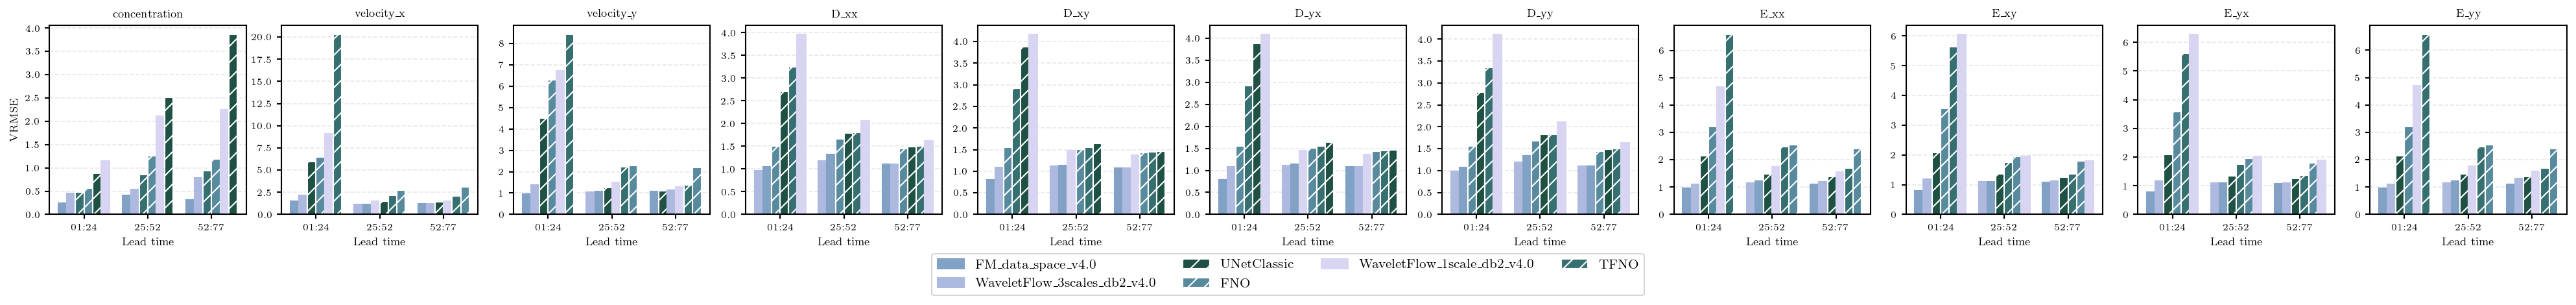

In [6]:
det_lookup = (
    stats_df[["model", "model_type"]]
    .drop_duplicates()
    .set_index("model")["model_type"]
    .to_dict()
)

horizons   = sorted(stats_df["horizon"].unique())
all_models = stats_df["model"].unique().tolist()
n_models   = len(all_models)
bar_width  = 0.8 / n_models

fig, axes = plt.subplots(
    1, n_fields,
    figsize=(2.4 * n_fields, 2.4 + 0.6),
    squeeze=False,
)
axes_flat = axes.flatten()

for ax, field in zip(axes_flat, field_names):
    table = stats_df[stats_df["field"] == field]

    for h_idx, horizon in enumerate(horizons):
        h_table = table[table["horizon"] == horizon]

        # aggregate + sort for this (field, horizon) group
        model_vals = (
            h_table.groupby("model")["vrmse"]
            .apply(aggregate)
            .sort_values()          # shortest bar first (best model)
            .dropna()
        )

        n_present = len(model_vals)
        offsets   = np.linspace(
            -(n_present - 1) / 2,
             (n_present - 1) / 2,
            n_present,
        ) * bar_width

        for offset, (model_name, val) in zip(offsets, model_vals.items()):
            is_det = det_lookup.get(model_name) == "deterministic"
            ax.bar(
                h_idx + offset, val,
                width=bar_width,
                color=model_palette[model_name],
                hatch="//" if is_det else "",
                edgecolor="white" if is_det else model_palette[model_name],
            )

    ax.set_xticks(range(len(horizons)))
    ax.set_xticklabels(horizons)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_ylabel("VRMSE" if ax is axes_flat[0] else "")
    ax.set_title(field)

# ── shared legend sorted by global mean VRMSE ─────────────────────────────
global_order = (
    stats_df.groupby("model")["vrmse"]
    .apply(aggregate)
    .sort_values()
    .index.tolist()
)

legend_handles = [
    mpatches.Patch(
        facecolor=model_palette[m],
        hatch="//" if det_lookup.get(m) == "deterministic" else "",
        edgecolor="white" if det_lookup.get(m) == "deterministic" else model_palette[m],
        label=m,
    )
    for m in global_order
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=4,
    frameon=True,
    fontsize="small",
)

fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.28)
#plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/vrmse_rollout_all_fields.png", dpi=300, bbox_inches='tight') #transparent=True)
plt.show()

# Plot: Aggregated VRMSE at different rollout steps/regimes

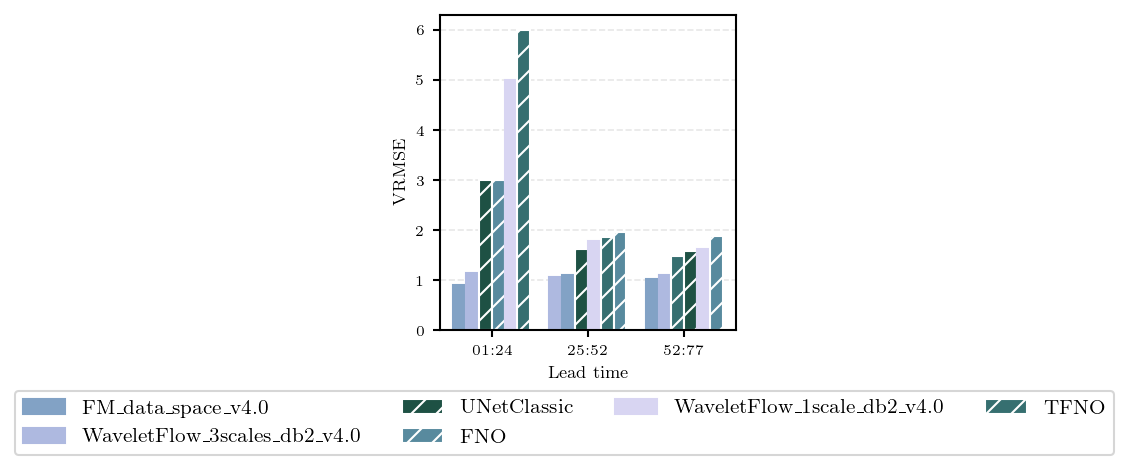

In [7]:
det_lookup = (
    stats_df[["model", "model_type"]]
    .drop_duplicates()
    .set_index("model")["model_type"]
    .to_dict()
)

horizons   = sorted(stats_df["horizon"].unique())
all_models = stats_df["model"].unique().tolist()
n_models   = len(all_models)
bar_width  = 0.8 / n_models

fig, axes = plt.subplots(
    1, 1,
    figsize=(2.4, 2.4 + 0.6),
    squeeze=False,
)
axes_flat = axes.flatten()

for ax, field in zip(axes_flat, field_names):
    table = stats_df

    for h_idx, horizon in enumerate(horizons):
        h_table = table[table["horizon"] == horizon]

        # aggregate + sort for this (field, horizon) group
        model_vals = (
            h_table.groupby("model")["vrmse"]
            .apply(aggregate)
            .sort_values()          # shortest bar first (best model)
            .dropna()
        )

        n_present = len(model_vals)
        offsets   = np.linspace(
            -(n_present - 1) / 2,
             (n_present - 1) / 2,
            n_present,
        ) * bar_width

        for offset, (model_name, val) in zip(offsets, model_vals.items()):
            is_det = det_lookup.get(model_name) == "deterministic"
            ax.bar(
                h_idx + offset, val,
                width=bar_width,
                color=model_palette[model_name],
                hatch="//" if is_det else "",
                edgecolor="white" if is_det else model_palette[model_name],
            )

    ax.set_xticks(range(len(horizons)))
    ax.set_xticklabels(horizons)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_ylabel("VRMSE" if ax is axes_flat[0] else "")
    #ax.set_title(field)

# ── shared legend sorted by global mean VRMSE ─────────────────────────────
global_order = (
    stats_df.groupby("model")["vrmse"]
    .apply(aggregate)
    .sort_values()
    .index.tolist()
)

legend_handles = [
    mpatches.Patch(
        facecolor=model_palette[m],
        hatch="//" if det_lookup.get(m) == "deterministic" else "",
        edgecolor="white" if det_lookup.get(m) == "deterministic" else model_palette[m],
        label=m,
    )
    for m in global_order
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=4,
    frameon=True,
    fontsize="small",
)

fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.28)
#plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/vrmse_rollout_all_fields.png", dpi=300, bbox_inches='tight') #transparent=True)
plt.show()

# HEADLINE

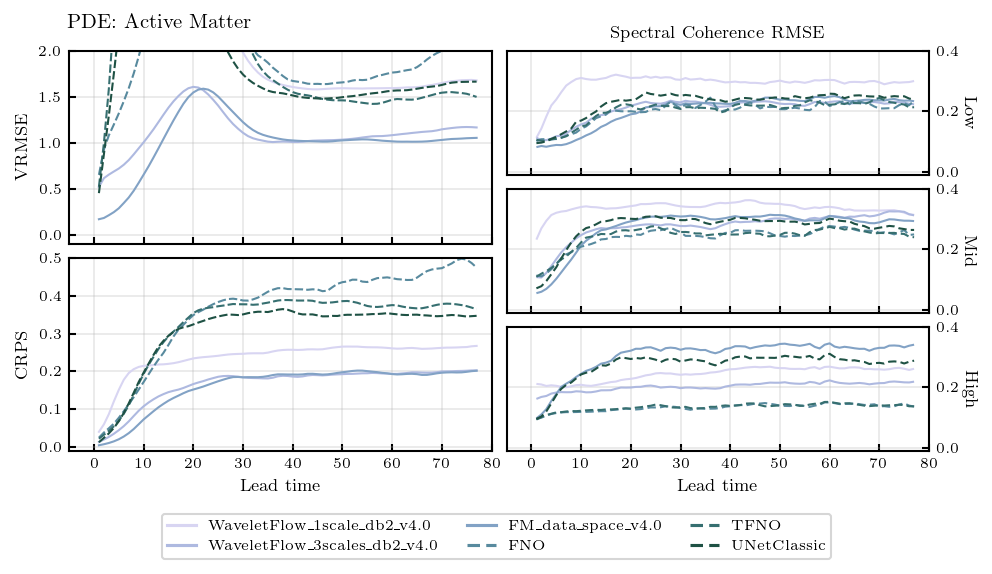

In [10]:
table = stats_df
dashes = {"generative": (1, 0), "deterministic": (4, 2)}

# ── Fine-grained y-limits per spectral band ───────────────────────────────────
band_ylims = {
    "Low":  (-0.01, 0.4),
    "Mid":  (-0.01, 0.4),
    "High": (-0.01, 0.4),
}

fig, axs = plt.subplot_mosaic(
    [[0, 2], [0, 2], [0, 3], [1, 3], [1, 4], [1, 4]],
    figsize=(6.5, 3.5),
    sharex=True,
    sharey=False,
)

for i, metric in enumerate(["VRMSE", "CRPS"]):
    ax = sns.lineplot(
        table, x="step", y=metric.lower(),
        hue="model", style="model_type",
        estimator=aggregate, errorbar=None,
        palette=model_palette, ax=axs[i],
    )
    ax.get_legend().remove()
    ax.grid(alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_xlim(-5, 80)
    if metric == "CRPS":
        ax.set_ylim(-0.01, 0.5)
    else:
        ax.set_ylim(-0.1, 2.0)
    ax.set_ylabel(metric.upper())
    ax.tick_params(direction="in")
    handles, labels = ax.get_legend_handles_labels()

for i, band in enumerate(["Low", "Mid", "High"], start=2):
    ax = sns.lineplot(
        table,
        #table[table["model_type"] == "generative"],
        x="step", y=f"rmse_c_{band.lower()}",
        hue="model", style="model_type",
        dashes=dashes, estimator=aggregate, errorbar=None,
        palette=model_palette, ax=axs[i],
    )
    ax.get_legend().remove()
    ax.grid(alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_xlim(-5, 80)
    ax.set_ylabel(band, labelpad=5.0)
    ax.set_ylim(*band_ylims[band])          # ← per-band control
    ax.tick_params(direction="in")
    ax.yaxis.set_label_position("right")
    ax.yaxis.label.set(rotation=-90, va="center")
    ax.yaxis.tick_right()
    if i == 2:
        ax.set_title("Spectral Coherence RMSE")

# ── Remove model/model_type headers and model_type value entries ─────────────
model_type_values = set(table["model_type"].unique())
labels_to_strip = {"model", "model_type"} | model_type_values

for i, label in reversed(list(enumerate(labels))):
    if label in labels_to_strip:
        handles.pop(i)
        labels.pop(i)

# ── Build model → model_type lookup ─────────────────────────────────────────
model_type_map = (
    table[["model", "model_type"]]
    .drop_duplicates()
    .set_index("model")["model_type"]
    .to_dict()
)

# ── Rebuild Line2D handles with correct color AND dash pattern ───────────────
LEGEND_LW = 1.5
legend_handles = []
for handle, label in zip(handles, labels):
    mtype = model_type_map.get(label)
    dash_pattern = dashes.get(mtype, (1, 0))
    ls = "-" if dash_pattern == (1, 0) else (0, dash_pattern)
    legend_handles.append(
        Line2D([0], [0], color=handle.get_color(), linestyle=ls, linewidth=LEGEND_LW)
    )

fig.align_labels()
fig.tight_layout(pad=0.25)
fig.subplots_adjust(bottom=0.18)

fig.legend(
    legend_handles, labels,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.04),
    frameon=True,
)

fig.text(0.06, 1.01, "PDE: Active Matter", fontsize=10, fontweight="bold", ha="left", va="top", transform=fig.transFigure)

plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/headline_active_matter.png", dpi=300, bbox_inches='tight', transparent=False)
plt.show()

# Plot: Averaged Power Spectrum RMSE across test trajectories

In [ ]:
from matplotlib.lines import Line2D

#zero_mean_fields = ['velocity_x', 'velocity_y', 'E_xx', 'E_xy', 'E_yx', 'E_yy']
#not_zero_mean_fields = [f for f in stats_df['field'].unique() if f not in zero_mean_fields]

#field = 'velocity_x'
#velocities = ['velocity_x', 'velocity_y']
#field = ['velocity_x', 'velocity_y']
#table = stats_df[stats_df['field'].isin(not_zero_mean_fields)].copy()
#table = stats_df[stats_df['field'].isin(field)]
#table = stats_df[stats_df['traj'] == 5].copy()
#field = ''
table = stats_df.copy()
#table = stats_df.copy()

fig, axs = plt.subplot_mosaic(
    [[0], [1], [2]],
    figsize=(3.2, 4.8),
    sharex=True,
    sharey=False,
)

dashes = {"generative": (1, 0), "deterministic": (4, 2)}

# Build a model → model_type lookup once
model_type_map = (
    table[["model", "model_type"]]
    .drop_duplicates()
    .set_index("model")["model_type"]
    .to_dict()
)

#table = (
#    stats_df
#    .groupby(["model", "model_type", "time"], as_index=False)
#    [[f"rmse_p_{b}" for b in ["low", "mid", "high"]]]
#    .agg(aggregate)
#)

for i, band in enumerate(["Low", "Mid", "High"]):
    ax = sns.lineplot(
        table,
        x="step",
        y=f"rmse_c_{band.lower()}",
        hue="model",
        style="model_type",
        dashes=dashes,
        estimator=aggregate,
        errorbar=None,
        palette=model_palette,
        ax=axs[i],
    )
    ax.grid(alpha=0.3)
    ax.set_xlabel("Lead time" if i == 2 else "")
    ax.set_xlim(-5, 80)
    ax.set_ylabel(band)
    ax.set_ylim(-0.1, 0.4)
    ax.tick_params(direction="in")
    ax.yaxis.set_label_position("right")
    ax.yaxis.label.set(rotation=-90, va="center")
    ax.yaxis.tick_right()
    if i == 0:
        #ax.set_title(f"Power Spectrum RMSE - {field}")
        #ax.set_title(f"Power Spectrum RMSE")
        ax.set_title(f"Spectral Coherence RMSE")


    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# ── Remove seaborn section headers ───────────────────────────────────────────
clean = [
    (h, l) for h, l in zip(handles, labels)
    if l not in ("model_type", "generative", "deterministic", "model")
]
handles_clean, labels_clean = zip(*clean)

"""# ── Fix legend handle linestyles to match the plot dashes ────────────────────
for handle, label in zip(handles_clean, labels_clean):
    mtype = model_type_map.get(label)
    if mtype is not None:
        dash_pattern = dashes.get(mtype, (1, 0))
        handle.set_linestyle((0, dash_pattern) if dash_pattern != (1, 0) else "-")

fig.align_labels()
fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.18)
fig.legend(
    handles_clean, labels_clean,
    loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.49, -0.045),
)"""

# ── Rebuild handles as proper Line2D tickers ──────────────────────────────────
legend_handles = []
for handle, label in zip(handles_clean, labels_clean):
    mtype = model_type_map.get(label)
    dash_pattern = dashes.get(mtype, (1, 0))
    ls = (0, dash_pattern) if dash_pattern != (1, 0) else "-"
    legend_handles.append(
        Line2D(
            [0], [0],
            color=handle.get_color(),
            linestyle=ls,
            linewidth=1.5,
        )
    )

fig.align_labels()
fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.18)
fig.legend(
    legend_handles, labels_clean,
    loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.49, -0.005),
    #handlelength=3,      # longer line segment (default is ~1.5)
    #handleheight=1.5,    # a bit more vertical room
    #handletextpad=0.5,   # tighten gap between line and label
)


#plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/psd_rmse_turbulent_radiative_layer_2D.png", dpi=300, bbox_inches='tight') #transparent=True)
plt.show()

# Spread-Skill Score - Individual Fields

In [ ]:
field = 'concentration'
table = stats_df[stats_df['field'] == field].copy()

# deterministic models have no spread/skill — drop them explicitly
table = table[table["model_type"] != "deterministic"]

fig, ax = plt.subplots(figsize=(5, 3))

sns.lineplot(
    table,
    x="step",
    y="spread_skill",
    hue="model",
    estimator=aggregate,
    errorbar=None,
    palette=model_palette,
    ax=ax,
)

# reference line: perfect calibration
ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--", label="Perfect calibration")

ax.get_legend().remove()
ax.grid(linestyle="--", alpha=0.3)
ax.set_xlabel("Lead time")
ax.set_xlim(-5, 80)
ax.set_ylim(0.5, 1.5)
ax.set_ylabel("Spread / Skill")
ax.tick_params(direction="in")
ax.set_title(f"{field}")

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles, labels,
    loc="lower right",
    fontsize="small",
    frameon=True,
    title=None,
)

fig.tight_layout(pad=0.33)
#plt.savefig(f"{outdir}/spread_skill_{field}.png", dpi=300, transparent=True)
plt.show()

# Spread-Skill Score - Average across Fields

In [ ]:
table = stats_df.copy()

# deterministic models have no spread/skill — drop them explicitly
table = table[table["model_type"] != "deterministic"]

fig, ax = plt.subplots(figsize=(5, 3))

sns.lineplot(
    table,
    x="step",
    y="spread_skill_new",
    hue="model",
    estimator=aggregate,
    errorbar=None,
    palette=model_palette,
    ax=ax,
)

# reference line: perfect calibration
ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--", label="Perfect calibration")

ax.get_legend().remove()
ax.grid(linestyle="--", alpha=0.3)
ax.set_xlabel("Lead time")
ax.set_xlim(-5, 80)
ax.set_ylim(0.5, 1.5)
ax.set_ylabel("Spread / Skill")
ax.tick_params(direction="in")
#ax.set_title(f"{field}")

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles, labels,
    loc="upper left",
    fontsize="small",
    frameon=True,
    title=None,
)

fig.tight_layout(pad=0.33)
#plt.savefig(f"{outdir}/spread_skill_{field}.png", dpi=300, transparent=True)
plt.show()

# Spread-Skill Score - All Fields

In [ ]:
# global model order for the legend (by mean spread/skill, descending —
# closer to 1 is better, so we sort by distance from 1)
global_order = (
    stats_df[stats_df["model_type"] != "deterministic"]
    .groupby("model")["spread_skill"]
    .apply(aggregate)
    .pipe(lambda s: (s - 1).abs().sort_values())   # closest to 1 first
    .index.tolist()
)

fig, axes = plt.subplots(
    1, n_fields,
    figsize=(3.2 * n_fields, 3.0 + 0.6),
    squeeze=False,
)
axes_flat = axes.flatten()

for ax, field in zip(axes_flat, field_names):
    table = (
        stats_df[
            (stats_df["field"] == field) &
            (stats_df["model_type"] != "deterministic")
        ].copy()
    )

    sns.lineplot(
        table,
        x="step",
        y="spread_skill",
        hue="model",
        hue_order=global_order,          # consistent ordering across panels
        estimator=aggregate,
        errorbar=None,
        palette=model_palette, # gen_palette,
        ax=ax,
    )

    # perfect-calibration reference
    ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--")

    ax.get_legend().remove()
    ax.grid(linestyle="--", alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_xlim(stats_df["time"].min() - 5, stats_df["time"].max() + 5)
    ax.set_ylim(0.5, 1.4)
    ax.set_ylabel("Spread / Skill" if ax is axes_flat[0] else "")
    ax.tick_params(direction="in")
    ax.set_title(field)

# ── shared bottom legend ───────────────────────────────────────────────────
legend_handles = [
    mlines.Line2D([], [],
        color=model_palette[m], #gen_palette[m],
        linewidth=1.8,
        label=m,
    )
    for m in global_order
]

# add the reference line entry
legend_handles.append(
    mlines.Line2D([], [],
        color="black", linewidth=0.8, linestyle="--",
        label="Perfect calibration",
    )
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.07),
    ncol=4,
    frameon=True,
    fontsize="small",
)

fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.28)
#plt.savefig(f"{outdir}/spread_skill_all_fields.png", dpi=300, transparent=True)
plt.show()

# CRPS - Individual fields

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

global_order = (
    stats_df.dropna(subset=["crps"])
    .groupby("model")["crps"]
    .apply(aggregate)
    .sort_values()
    .index.tolist()
)

fig, axes = plt.subplots(
    1, n_fields,
    figsize=(3.2 * n_fields, 3.0 + 0.6),
    sharey=False,          # ← independent y-axes per panel
    squeeze=False,
)
axes_flat = axes.flatten()

for ax, field in zip(axes_flat, field_names):
    table = stats_df[stats_df["field"] == field].dropna(subset=["crps"])

    # ── generative ─────────────────────────────────────────────────────────
    gen_table = table[table["model_type"] != "deterministic"]
    if not gen_table.empty:
        sns.lineplot(
            gen_table,
            x="step",
            y="crps",
            hue="model",
            hue_order=[m for m in global_order if m in gen_table["model"].unique()],
            estimator=aggregate,
            errorbar=None,
            palette=model_palette,
            linestyle="-",
            ax=ax,
        )

    # ── deterministic ──────────────────────────────────────────────────────
    det_table = table[table["model_type"] == "deterministic"]
    if not det_table.empty:
        sns.lineplot(
            det_table,
            x="step",
            y="crps",
            hue="model",
            hue_order=[m for m in global_order if m in det_table["model"].unique()],
            estimator=aggregate,
            errorbar=None,
            palette=model_palette,
            linestyle="--",
            ax=ax,
        )

    ax.get_legend().remove()
    ax.grid(linestyle="--", alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_xlim(stats_df["step"].min() - 5, stats_df["step"].max() + 5)
    ax.set_ylim(bottom=0)
    ax.set_ylabel("CRPS" if ax is axes_flat[0] else "")
    ax.tick_params(direction="in")
    ax.set_title(field)

# ── shared legend ──────────────────────────────────────────────────────────
legend_handles = [
    mlines.Line2D([], [],
        color=model_palette[m],
        linewidth=1.8,
        linestyle="--" if det_lookup.get(m) == "deterministic" else "-",
        label=m,
    )
    for m in global_order
]
#legend_handles += [
#    mlines.Line2D([], [], color="grey", linewidth=1.8, linestyle="-",  label="Generative"),
#    mlines.Line2D([], [], color="grey", linewidth=1.8, linestyle="--", label="Deterministic"),
#]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=3,
    frameon=True,
    fontsize="small",
)

fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.28)
#plt.savefig(f"{outdir}/crps_all_fields.png", dpi=300, transparent=True)
plt.show()

# CRPS - Average across fields

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

global_order = (
    stats_df.dropna(subset=["crps"])
    .groupby("model")["crps"]
    .apply(aggregate)
    .sort_values()
    .index.tolist()
)

fig, axes = plt.subplots(
    1, 1,
    figsize=(5.2 * 1, 3.0 + 0.6),
    sharey=False,          # ← independent y-axes per panel
    squeeze=False,
)
axes_flat = axes.flatten()

for ax, field in zip(axes_flat, field_names):
    #table = stats_df[stats_df["field"] == field].dropna(subset=["crps"])
    table = stats_df.dropna(subset=["crps"])

    # ── generative ─────────────────────────────────────────────────────────
    gen_table = table[table["model_type"] != "deterministic"]
    if not gen_table.empty:
        sns.lineplot(
            gen_table,
            x="step",
            y="crps",
            hue="model",
            hue_order=[m for m in global_order if m in gen_table["model"].unique()],
            estimator=aggregate,
            errorbar=None,
            palette=model_palette,
            linestyle="-",
            ax=ax,
        )

    # ── deterministic ──────────────────────────────────────────────────────
    det_table = table[table["model_type"] == "deterministic"]
    if not det_table.empty:
        sns.lineplot(
            det_table,
            x="step",
            y="crps",
            hue="model",
            hue_order=[m for m in global_order if m in det_table["model"].unique()],
            estimator=aggregate,
            errorbar=None,
            palette=model_palette,
            linestyle="--",
            ax=ax,
        )

    ax.get_legend().remove()
    ax.grid(linestyle="--", alpha=0.3)
    ax.set_xlabel("Lead time")
    ax.set_xlim(stats_df["step"].min() - 5, stats_df["step"].max() + 5)
    ax.set_ylim(bottom=-0.05, top=0.5)
    ax.set_ylabel("CRPS" if ax is axes_flat[0] else "")
    ax.tick_params(direction="in")
    #ax.set_title(field)

# ── shared legend ──────────────────────────────────────────────────────────
legend_handles = [
    mlines.Line2D([], [],
        color=model_palette[m],
        linewidth=1.8,
        linestyle="--" if det_lookup.get(m) == "deterministic" else "-",
        label=m,
    )
    for m in global_order
]

#legend_handles += [
#    mlines.Line2D([], [], color="grey", linewidth=1.8, linestyle="-",  label="Generative"),
#    mlines.Line2D([], [], color="grey", linewidth=1.8, linestyle="--", label="Deterministic"),
#]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.55, -0.07),
    ncol=2,
    frameon=True,
    fontsize="small",
)

fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.28)
#plt.savefig(f"{PROJECT_ROOT}/experiments/{well_dataset_name}/figures/crps_turbulent_radiative_layer_2D.png", dpi=300, bbox_inches='tight') #, transparent=True)
plt.show()

# PSD

In [ ]:
from matplotlib import ticker
import math, numpy as np

gt_label      = "Ground-truth"
all_models    = ['WaveletFlow_1scale_db2_v4.0', 
                 'WaveletFlow_3scales_db2_v4.0', 
                 'FM_data_space_v4.0', 
                 'UNetConvNext', gt_label]

non_gt_models = [m for m in all_models if m != gt_label]

wl_min, wl_max = 1, 8
table_ds = psd_df[
    psd_df['model'].isin(all_models) &
    (psd_df["band"] != "vhigh") &
    (psd_df["wavelength"] >= wl_min) &
    (psd_df["wavelength"] <= wl_max)
].copy()

fig, axs = plt.subplots(
    1, len(field_names),
    figsize=(4.5 * len(field_names), 3.8),
    sharey=False, squeeze=False,
)

for col_idx, field in enumerate(field_names):
    ax = axs[0, col_idx]
    #df_field = table_ds[table_ds["field"] == field]  # filter by field
    df_field = table_ds

    # ── Non-GT models ────────────────────────────────────────────────────
    sns.lineplot(
        data=df_field[df_field["model"] != gt_label],
        x="wavelength", y="psd",
        hue="model", 
        hue_order=non_gt_models,
        palette={m: model_palette[m] for m in non_gt_models},
        estimator=aggregate, 
        errorbar=None,
        linewidth=1.5, 
        ax=ax,
    )

    # ── Ground truth ──────────────────────────────────────────────────────
    sns.lineplot(
        data=df_field[df_field["model"] == gt_label],
        x="wavelength", 
        y="psd",
        color="black", 
        linestyle=(0, (4, 2)),
        estimator=aggregate, 
        errorbar=None,
        linewidth=2.0, 
        label="_nolegend_", ax=ax,
    )

    # ── Log-log, wavelength axis inverted (large scale → left) ───────────
    ax.set_xscale("log", base=2)
    ax.set_yscale("log", base=2)
    ax.invert_xaxis()

    # ── Wavelength ticks as powers of 2 ───────────────────────────────────
    wl       = df_field["wavelength"].replace([np.inf], np.nan).dropna()
    exp_min  = math.floor(math.log2(wl.min()))
    exp_max  = math.ceil(math.log2(wl.max()))
    wl_ticks = [2**e for e in range(exp_min, exp_max + 1)]
    ax.set_xticks(wl_ticks)
    ax.xaxis.set_major_formatter(
        ticker.FuncFormatter(
            lambda v, _: rf"$2^{{{int(round(math.log2(v)))}}}$" if v > 0 else ""
        )
    )
    ax.xaxis.set_minor_locator(ticker.NullLocator())

    # ── Legend ─────────────────────────────────────────────────────────────
    handles, labels = ax.get_legend_handles_labels()
    gt_handle = mlines.Line2D([], [], color="black", linestyle=(0, (4, 2)),
                              linewidth=1.5, label=gt_label)
    ax.legend(handles + [gt_handle], labels + [gt_label],
              fontsize=8, framealpha=0.7)

    ax.set_title(field, fontsize=10)
    ax.set_xlabel("Wavelength", fontsize=9)
    ax.set_ylabel("PSD" if col_idx == 0 else "", fontsize=9)
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

# PSD Ratio

In [ ]:
psd_df.columns

In [ ]:
import math
import numpy as np
from matplotlib import ticker
import matplotlib.lines as mlines

# ── Config ────────────────────────────────────────────────────────────────
steps_to_show = [2, 4, 8, 16, 32, 64]
gt_label      = "Ground-truth"
field         = "buoyancy"           # fix one field; loop over field_names if needed

all_models    = [
    'WaveletFlow_1scale_db2_v4.0',
    'WaveletFlow_3scales_db2_v4.0',
    'FM_data_space_v4.0',
    gt_label,
]
non_gt_models = [m for m in all_models if m != gt_label]
wl_min, wl_max = 1, 128

# ── Step 1: unique (Ra, Pr) rows — sorted for reproducibility ─────────────
traj_combos = (
    psd_df[["Rayleigh", "Prandtl"]]
    .drop_duplicates()
    .sort_values(["Rayleigh", "Prandtl"])
    .reset_index(drop=True)
)
n_traj  = len(traj_combos)
n_steps = len(steps_to_show)

# ── Step 2: GT baseline per (rayleigh, prandtl, field, band, wavelength) ──
gt_psd = (
    psd_df[
        (psd_df["model"] == gt_label) &
        (psd_df["field"] == field)
    ]
    .groupby(["Rayleigh", "Prandtl", "band", "wavelength"])["psd"]
    .agg(aggregate)
    .reset_index()
    .rename(columns={"psd": "psd_gt"})
)

# ── Step 3: filter & merge GT ─────────────────────────────────────────────
ratio_ds = psd_df[
    psd_df["model"].isin(non_gt_models) &
    psd_df["step"].isin(steps_to_show) &
    (psd_df["field"] == field) &
    (psd_df["band"] != "vhigh") &
    (psd_df["wavelength"] >= wl_min) &
    (psd_df["wavelength"] <= wl_max)
].copy()

ratio_ds = ratio_ds.merge(
    gt_psd, on=["Rayleigh", "Prandtl", "band", "wavelength"], how="left"
)
ratio_ds["psd_ratio"] = ratio_ds["psd"] / ratio_ds["psd_gt"]

# ── Step 4: build figure — rows = (Ra,Pr) combos, cols = steps ────────────
fig, axs = plt.subplots(
    n_traj, n_steps,
    figsize=(3.2 * n_steps, 2.6 * n_traj),
    sharey="row",
    sharex=True,
    squeeze=False,
)

for row_idx, (_, traj) in enumerate(traj_combos.iterrows()):
    ra, pr = traj["Rayleigh"], traj["Prandtl"]
    df_traj = ratio_ds[
        (ratio_ds["Rayleigh"] == ra) &
        (ratio_ds["Prandtl"] == pr)
    ]

    for col_idx, step in enumerate(steps_to_show):
        ax    = axs[row_idx, col_idx]
        df_plot = df_traj[df_traj["step"] == step]

        # ── lines per model ───────────────────────────────────────────────
        sns.lineplot(
            data=df_plot,
            x="wavelength",
            y="psd_ratio",
            hue="model",
            hue_order=non_gt_models,
            palette={m: model_palette[m] for m in non_gt_models},
            estimator=aggregate,
            errorbar=("sd", 1),
            linewidth=1.5,
            ax=ax,
        )

        # ── reference & shading ───────────────────────────────────────────
        ax.axhline(1.0, color="black", linestyle=(0, (4, 2)), linewidth=1.2)
        ax.axhspan(0, 1.0, alpha=0.04, color="red", zorder=0)

        # ── log x axis & ticks ────────────────────────────────────────────
        ax.set_xscale("log", base=2)
        wl_vals = df_plot["wavelength"].replace([np.inf], np.nan).dropna()
        if len(wl_vals):
            exp_min = math.floor(math.log2(wl_vals.min()))
            exp_max = math.ceil(math.log2(wl_vals.max()))
            ticks   = [2**e for e in range(exp_min, exp_max + 1)]
            ax.set_xticks(ticks)
            ax.xaxis.set_major_formatter(
                ticker.FuncFormatter(
                    lambda v, _: rf"$2^{{{int(round(math.log2(v)))}}}$" if v > 0 else ""
                )
            )
        ax.xaxis.set_minor_locator(ticker.NullLocator())
        ax.invert_xaxis()

        # ── titles / labels ───────────────────────────────────────────────
        if row_idx == 0:
            ax.set_title(f"Step {step}", fontsize=10)
        if col_idx == 0:
            ax.set_ylabel(
                f"Ra={ra:.0e}, Pr={pr}\n" + r"$R(\lambda)=\hat{S}/S_{GT}$",
                fontsize=8,
            )
        else:
            ax.set_ylabel("")
        ax.set_xlabel("Wavelength" if row_idx == n_traj - 1 else "")

        # ── legend: only top-right cell ───────────────────────────────────
        if row_idx == 0 and col_idx == n_steps - 1:
            handles, labels = ax.get_legend_handles_labels()
            ref_handle = mlines.Line2D(
                [], [], color="black", linestyle=(0, (4, 2)),
                linewidth=1.2, label="GT reference (R=1)"
            )
            ax.legend(
                handles + [ref_handle],
                labels  + ["GT reference (R=1)"],
                fontsize=7, framealpha=0.7, loc="best",
            )
        else:
            leg = ax.get_legend()
            if leg:
                leg.remove()

        ax.grid(alpha=0.3)
        ax.set_ylim(bottom=0)

fig.suptitle(
    rf"Spectral ratio $R(\lambda)$ — field: {field} — closer to 1 is better",
    fontsize=11, y=1.01,
)
fig.tight_layout(pad=0.4)
plt.show()

# Tables 

In [ ]:
def highlight_min_per_field_horizon(df: pd.DataFrame) -> pd.DataFrame:
    styles = pd.DataFrame("", index=df.index, columns=df.columns)
    fields = df.index.get_level_values("field").unique()

    for field in fields:
        field_mask = df.index.get_level_values("field") == field
        sub = df.loc[field_mask]
        for col in df.columns:
            min_idx = sub[col].idxmin()
            styles.loc[min_idx, col] = "font-weight: bold"

    return styles

In [ ]:
table = stats_df[["model", "field", "horizon", "vrmse"]]

table = table.groupby(["model", "field", "horizon"]).agg(aggregate).round(3).reset_index()
table = table.pivot(index=["model", "field"], columns="horizon", values=["vrmse"])
table.style.apply(highlight_min_per_field_horizon, axis=None)
# print(table.to_latex(float_format="%.3f"))
#table

In [ ]:
print(table.to_latex(float_format="%.3f"))